# Compare gold forecasting models
Run any model notebook first. This notebook reads saved predictions and never retrains models.
Models are compared on the intersection of observed targets and common forecast origins.
The persistence baseline predicts the gold price observed at the origin.

In [7]:
from pathlib import Path
import os
# Limit CPU threads before importing optional numerical/model libraries.
os.environ.setdefault('TF_CPP_MIN_LOG_LEVEL', '2')
os.environ.setdefault('TF_NUM_INTRAOP_THREADS', '2')
os.environ.setdefault('TF_NUM_INTEROP_THREADS', '1')
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from model_lib.preprocessing import ROOT, load_config
# Load the shared experiment configuration.
cfg = load_config()
pd.set_option('display.max_columns', 20)
print('Project:', ROOT)
print('Target:', cfg['target_name'], '| horizons:', cfg['horizons'])

Project: /home/kosala/git-repos/exps/gold_forecasting
Target: Kitco Price (USD) | horizons: [1, 5, 20]


## 1. Load development results and check coverage

In [8]:
from model_lib.model_training import compare_results
# Compare models only on the intersection of observable targets.
predictions, results, coverage = compare_results('cv')
display(coverage)
print('Models currently available:', predictions.model.unique().tolist())
display(results)

,total_predictions,observed_targets,common_predictions
model,,,
gru,78,65,65
lstm,78,65,65
prophet,78,65,65
xgboost,78,65,65


Models currently available: ['gru', 'lstm', 'prophet', 'xgboost', 'persistence', 'trailing_drift']


,model,fold,horizon,n,MAE,RMSE,MAPE,MASE,baseline_MAE,skill_vs_persistence
0,gru,cv_1,1,5,10.578261,13.467332,0.536885,1.099124,9.5800,-0.104203
1,gru,cv_1,5,5,22.507396,29.893998,1.154773,2.338609,19.6200,-0.147166
2,gru,cv_1,20,4,50.652733,51.310495,2.604017,5.263022,22.6500,-1.236324
3,gru,cv_2,1,5,11.695415,18.878469,0.573431,1.220392,11.2540,-0.039223
4,gru,cv_2,5,4,46.374423,59.119552,2.169473,4.839075,46.2425,-0.002853
...,...,...,...,...,...,...,...,...,...,...
85,xgboost,cv_4,5,4,96.459434,122.948701,3.142288,9.594383,99.7900,0.033376
86,xgboost,cv_4,20,4,117.322804,156.682476,3.833269,11.669568,122.1025,0.039145
87,xgboost,cv_5,1,3,42.082778,48.978847,1.270951,3.986759,36.3700,-0.157074
88,xgboost,cv_5,5,5,66.829161,79.757384,1.807232,6.331136,80.4840,0.169659


## 2. Compare forecasts against observed prices

The following figures use only the common observable targets:
1. mean forecast path per model on the full observed history;
2. one panel per fold with training context plus test actuals;
3. actual vs predicted scatter per horizon;
4. overall and per-horizon MAE ranking.
All figures are saved under `artifacts/comparison/plots/`.

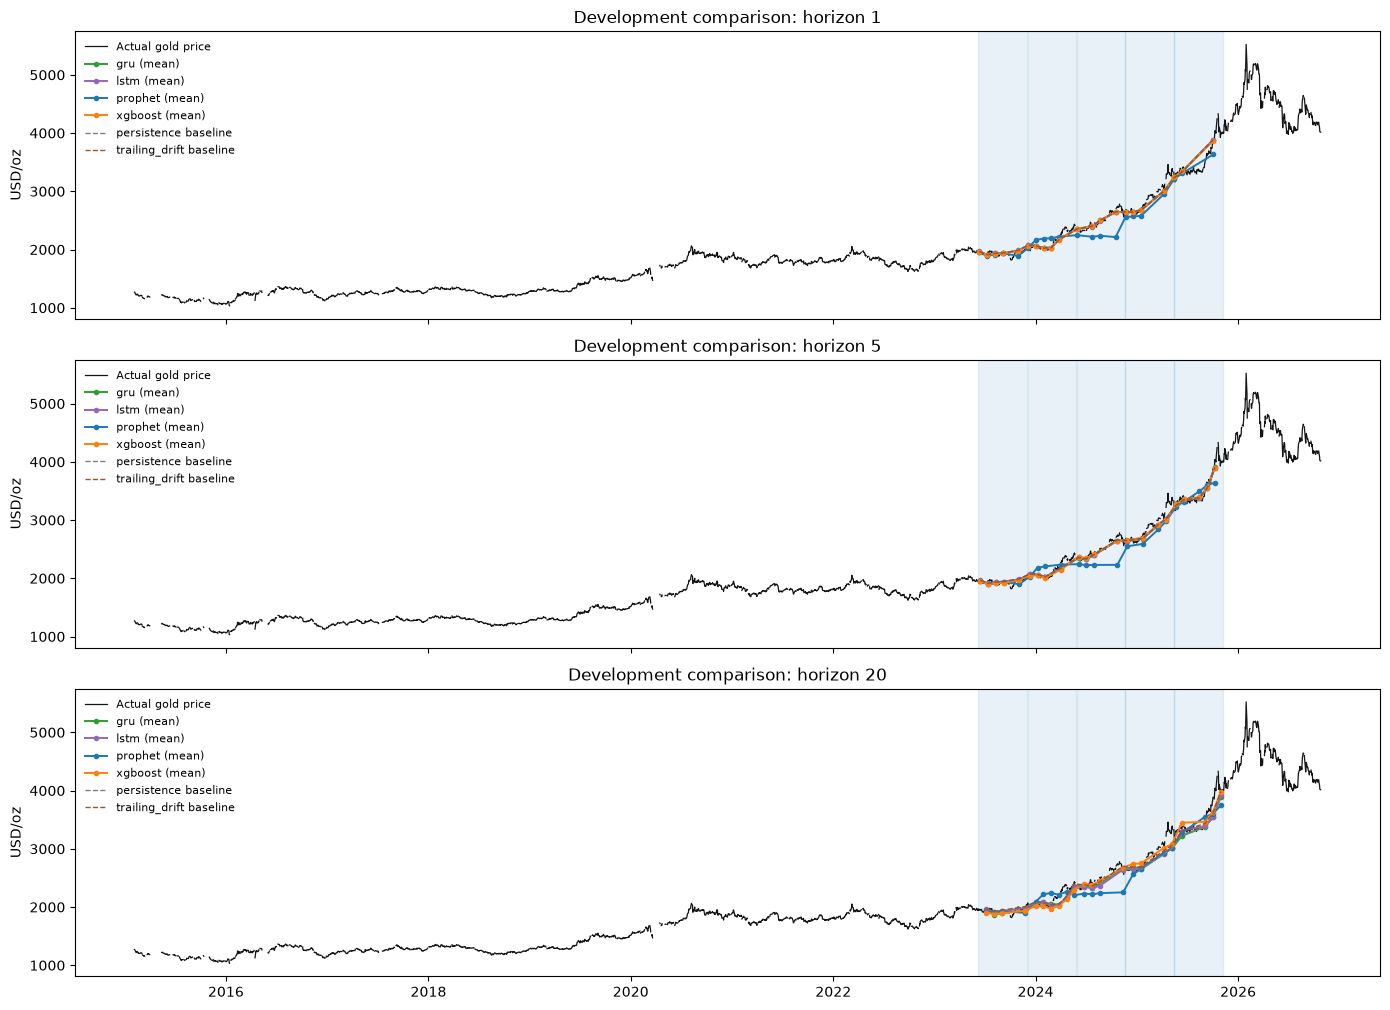

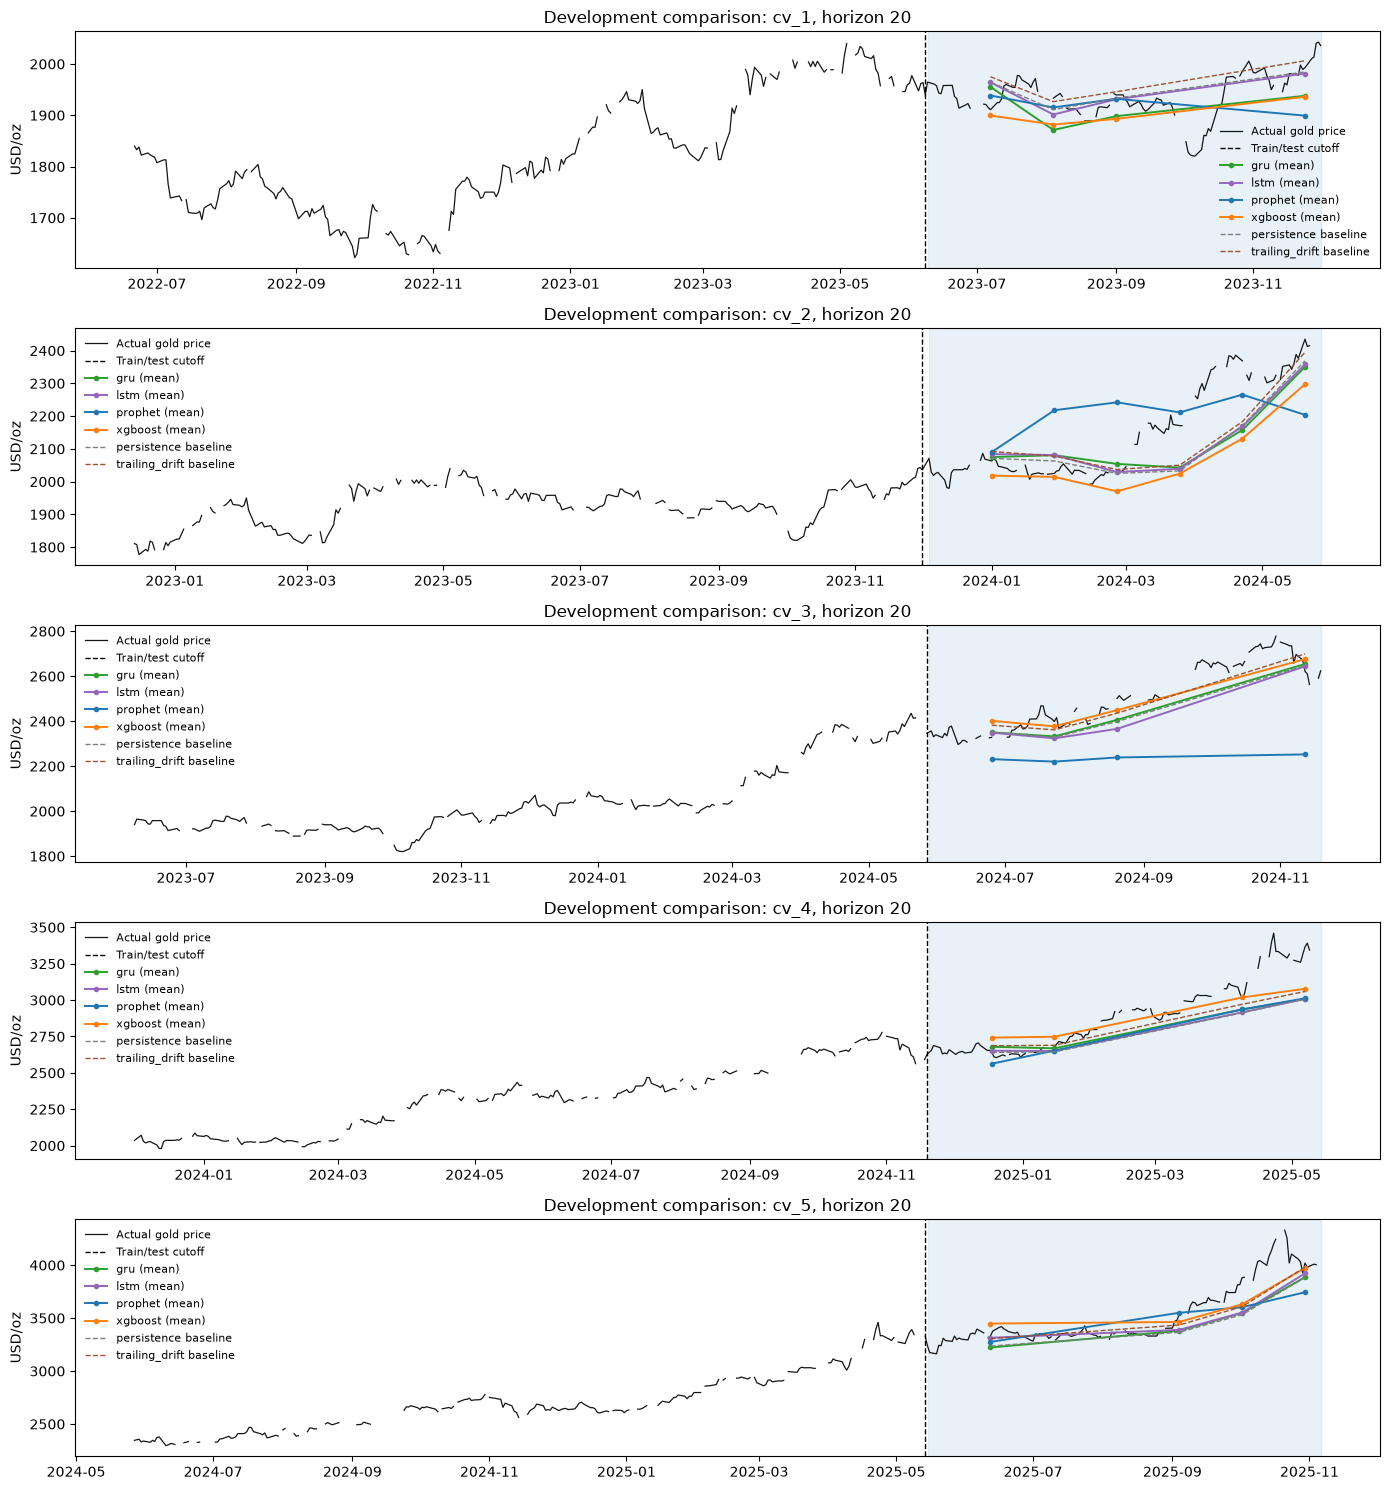

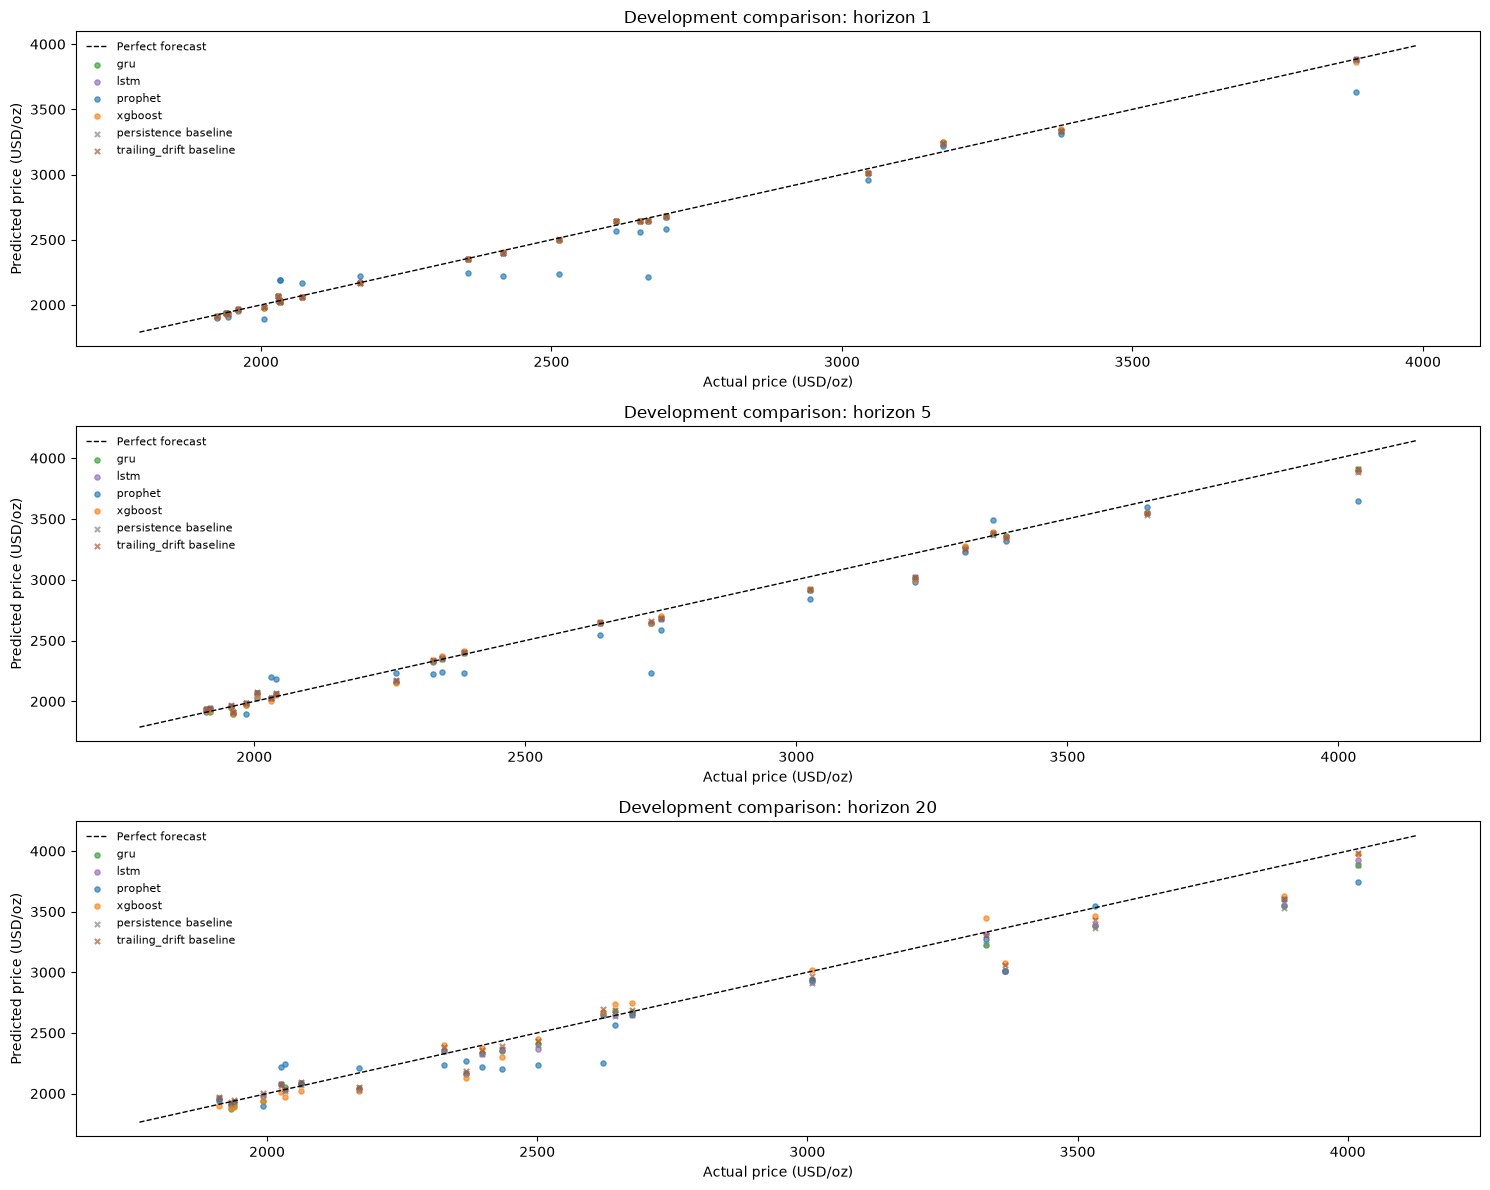

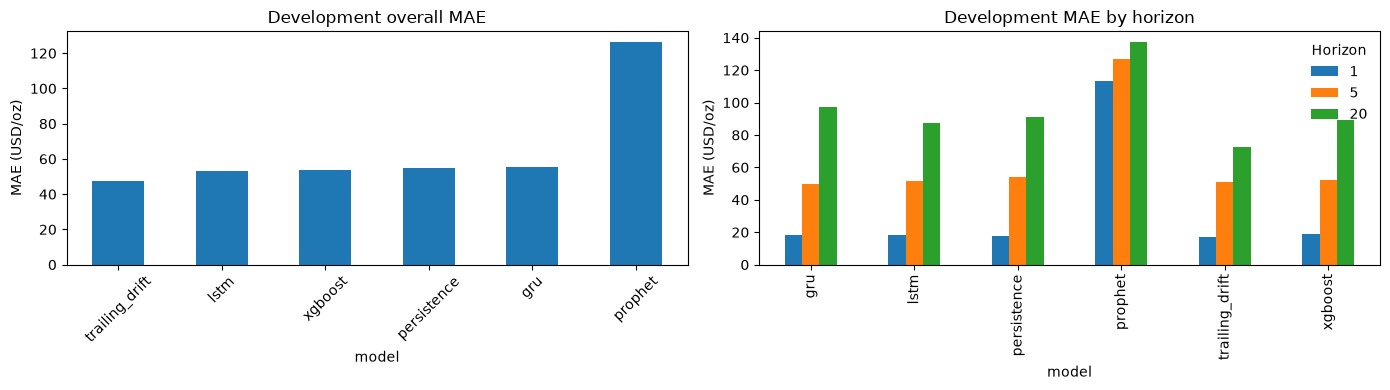

[PosixPath('/home/kosala/git-repos/exps/gold_forecasting/artifacts/comparison/plots/comparison_error_ranking.png')]

In [9]:
from model_lib.preprocessing import load_prepared
from model_lib.reporting.plots import (
    plot_comparison_actual_and_forecasts,
    plot_comparison_by_fold,
    plot_comparison_scatter,
    plot_comparison_error_ranking,
)

panel, _features, folds = load_prepared()
out_dir = ROOT / 'artifacts' / 'comparison'
plot_comparison_actual_and_forecasts(predictions, panel, folds, cfg, out_dir, stage='cv')
plot_comparison_by_fold(predictions, panel, folds, cfg, out_dir, stage='cv')
plot_comparison_scatter(predictions, panel, folds, cfg, out_dir, stage='cv')
plot_comparison_error_ranking(predictions, cfg, out_dir, stage='cv')

## 3. Compare pooled errors and fold stability

horizon,1,5,20
model,,,
gru,18.181495,49.762816,96.979697
lstm,18.568483,51.711950,87.261736
persistence,17.695238,54.079091,91.137273
prophet,113.604037,127.048800,137.090181
trailing_drift,17.033942,50.991331,72.452388
xgboost,18.911336,52.379709,89.083322


mean        std        min         max
model          horizon                                              
gru            1         19.953863  12.282829  10.578261   39.539538
               5         50.577667  30.023104  22.507396   96.658228
               20        98.126227  54.207298  50.652733  181.709598
lstm           1         20.125558  10.446220  11.491975   35.733724
               5         52.433925  29.375026  20.107087   93.973846
               20        87.814707  47.461936  26.248442  146.796870
persistence    1         19.356800  11.510920   9.580000   36.370000
               5         54.481800  34.669667  19.620000   99.790000
               20        92.648667  63.983930  22.650000  187.180000
prophet        1        118.843152  83.931393  36.619167  258.734312
               5        130.778144  69.661783  35.385345  215.996715
               20       137.394878  68.071653  36.693062  226.704686
trailing_drift 1         18.654064  11.570886   9.335159   36.193558
               5         51.612589  28.969152  21.806111   92.534841
               20        72.485529  34.506903  22.714286  109.079445
xgboost        1         20.698820  12.955514  11.647045   42.082778
               5         53.346613  29.694644  18.592170   96.459434
               20        87.323101  38.326989  41.516066  120.875028

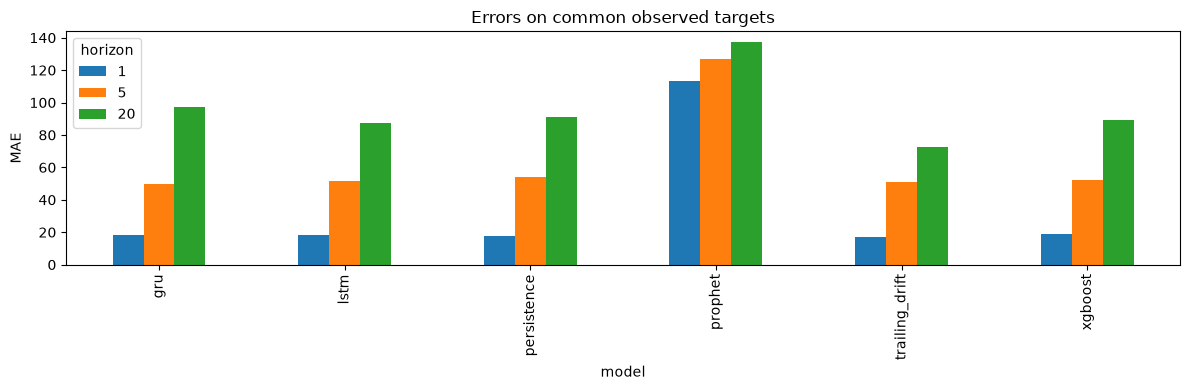

In [10]:
# Pooled MAE weights individual forecast errors equally within each horizon.
observed = predictions.dropna(subset=['actual', 'prediction']).copy()
observed['absolute_error'] = (observed.prediction - observed.actual).abs()
pooled = observed.groupby(['model', 'horizon']).absolute_error.mean().unstack('horizon')
display(pooled)
pooled.plot.bar(figsize=(12, 4), ylabel='MAE', title='Errors on common observed targets')
plt.tight_layout()
display(results.groupby(['model', 'horizon']).MAE.agg(['mean', 'std', 'min', 'max']))

## 4. Inspect residuals through time

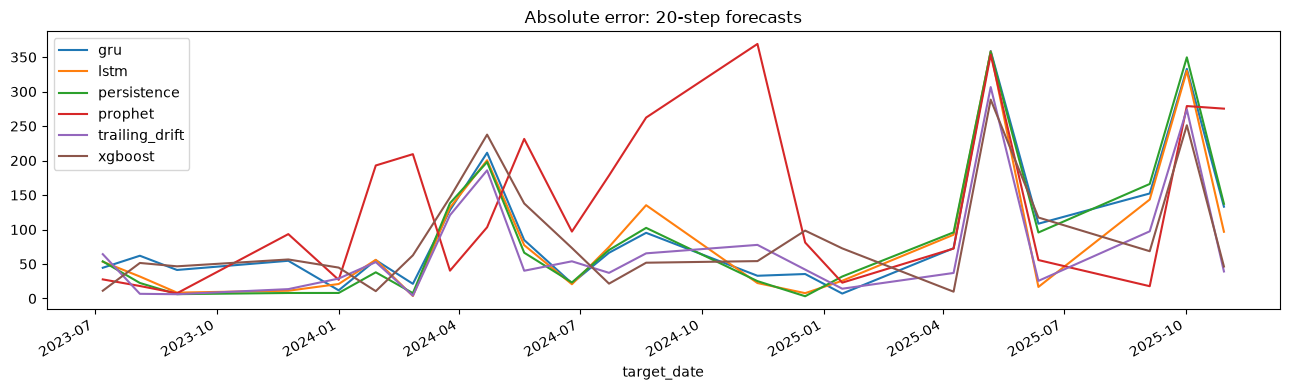

In [11]:
# Track the absolute error path through time, per model.
horizon = cfg['horizons'][-1]
fig, ax = plt.subplots(figsize=(13, 4))
for model, group in observed.loc[observed.horizon.eq(horizon)].groupby('model'):
    group.sort_values('target_date').plot(x='target_date', y='absolute_error', ax=ax, label=model)
ax.set_title(f'Absolute error: {horizon}-step forecasts')
plt.tight_layout()

## 5. Inspect external-feature selection
Inner scores show which feature group was selected without using the corresponding outer block.
Interpret importance as predictive association, not a causal explanation.

In [12]:
# Selection must use inner folds only; holdout results stay separate.
tables = []
for path in sorted((ROOT / 'artifacts').glob('*/inner_selection.csv')):
    table = pd.read_csv(path)
    table['model'] = path.parent.name
    tables.append(table)
if tables:
    selection = pd.concat(tables, ignore_index=True)
    selection['group'] = selection.params.map(lambda value: json.loads(value)['group'])
    display(selection.groupby(['model', 'group']).inner_MAE.agg(['mean', 'std', 'count']))

mean        std  count
model   group                                  
gru     external    45.113540  18.253046     10
        gold_only   44.233956  22.790522      5
lstm    external    47.765875  14.287217     10
        gold_only   44.192120  22.889914      5
prophet external    91.918513  38.572467     10
        gold_only  159.621199  66.395229      5
xgboost external    48.431270  18.076692     10
        gold_only   49.212387  21.195865      5

## 6. Review final holdout results if available
Keep these separate from development results. Do not retune using this table.
The current package does not claim uncertainty intervals or verified real-time release vintages.

In [13]:
# Show each model's holdout results only after development is complete.
holdout_files = list((ROOT / 'artifacts').glob('*/holdout_predictions.csv'))
if holdout_files:
    holdout_predictions, holdout_results, holdout_coverage = compare_results('holdout')
    display(holdout_coverage)
    display(holdout_results)
else:
    print('No holdout results yet.')

,total_predictions,observed_targets,common_predictions
model,,,
gru,36,32,32
lstm,36,32,32
prophet,36,32,32
xgboost,36,32,32


,model,fold,horizon,n,MAE,RMSE,MAPE,MASE,baseline_MAE,skill_vs_persistence
0,gru,holdout,1,11,64.183761,114.056500,1.357544,5.509180,58.936364,-0.089035
1,gru,holdout,5,9,172.128901,257.118997,3.746771,14.774595,162.440000,-0.059646
2,gru,holdout,20,12,335.140564,447.149244,7.143136,28.766616,338.485000,0.009881
3,lstm,holdout,1,11,60.251516,114.788449,1.268776,5.171657,58.936364,-0.022315
4,lstm,holdout,5,9,164.927782,251.375181,3.609102,14.156490,162.440000,-0.015315
5,lstm,holdout,20,12,331.459008,457.261541,7.053936,28.450611,338.485000,0.020757
6,persistence,holdout,1,11,58.936364,111.663791,1.243487,5.058772,58.936364,0.000000
7,persistence,holdout,5,9,162.440000,245.604486,3.569692,13.942953,162.440000,0.000000
8,persistence,holdout,20,12,338.485000,460.709830,7.189707,29.053684,338.485000,0.000000
9,prophet,holdout,1,11,421.649937,519.385348,9.528129,36.192103,58.936364,-6.154326


## 7. Optional holdout comparison plots

These figures appear only when all models have observed holdout predictions:
- `holdout_comparison_actual_and_forecasts.png`
- `holdout_comparison_by_fold.png`
- `holdout_comparison_actual_vs_predicted_scatter.png`
- `holdout_comparison_error_ranking.png`

They use the same helper functions as the development comparison plots, with
`stage='holdout'` so only the untouched holdout block is plotted.

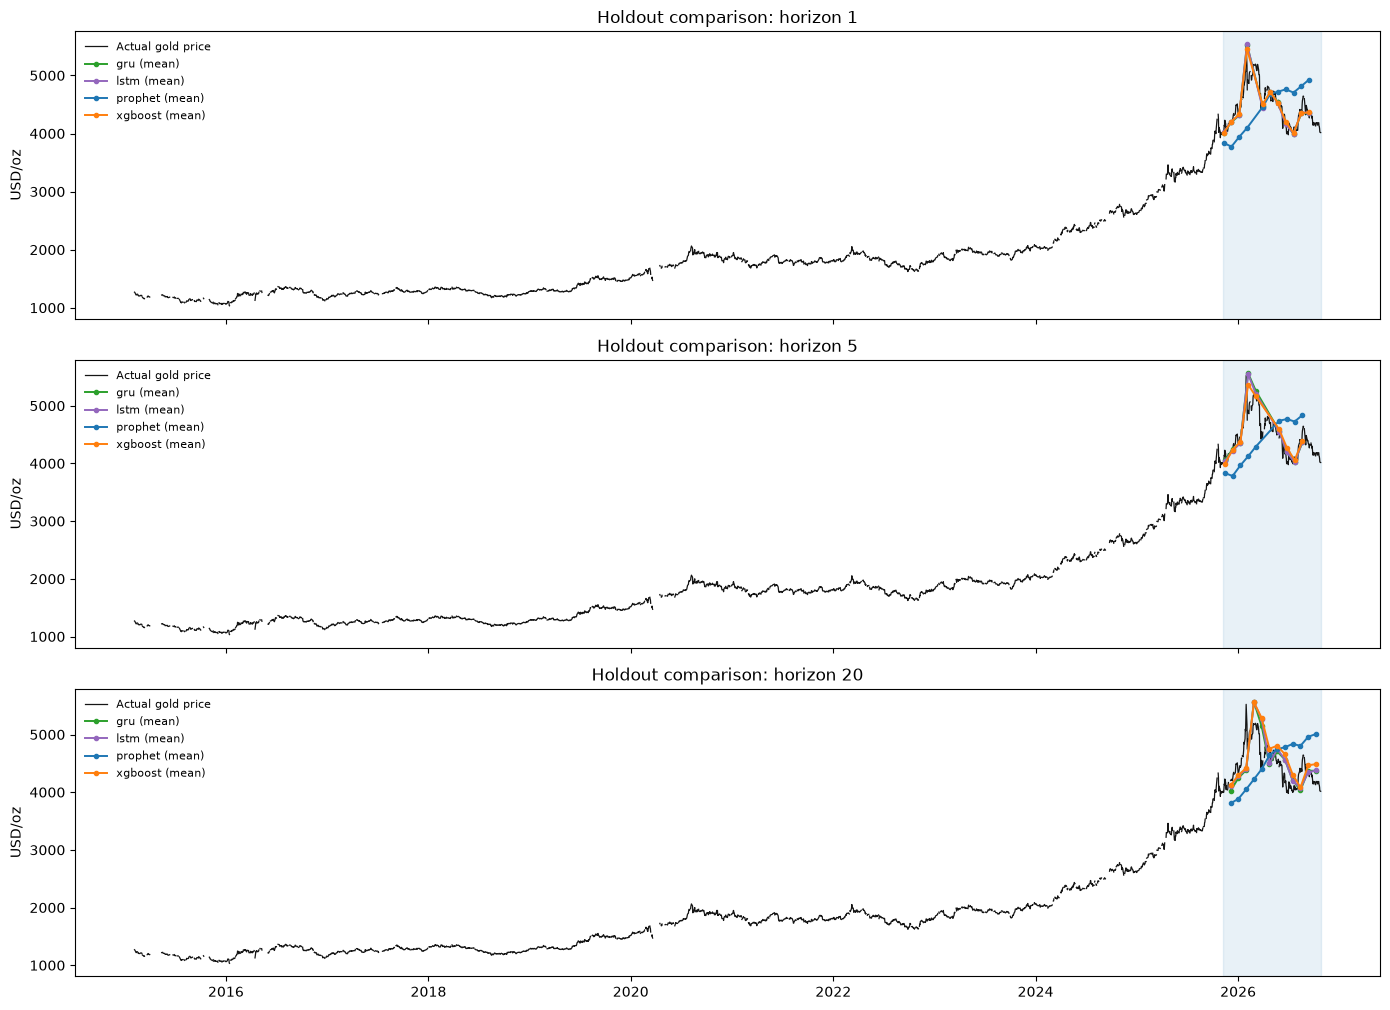

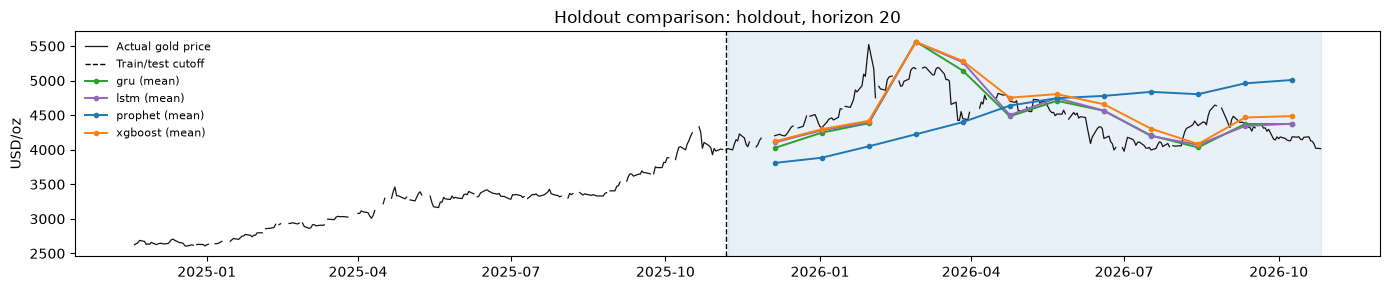

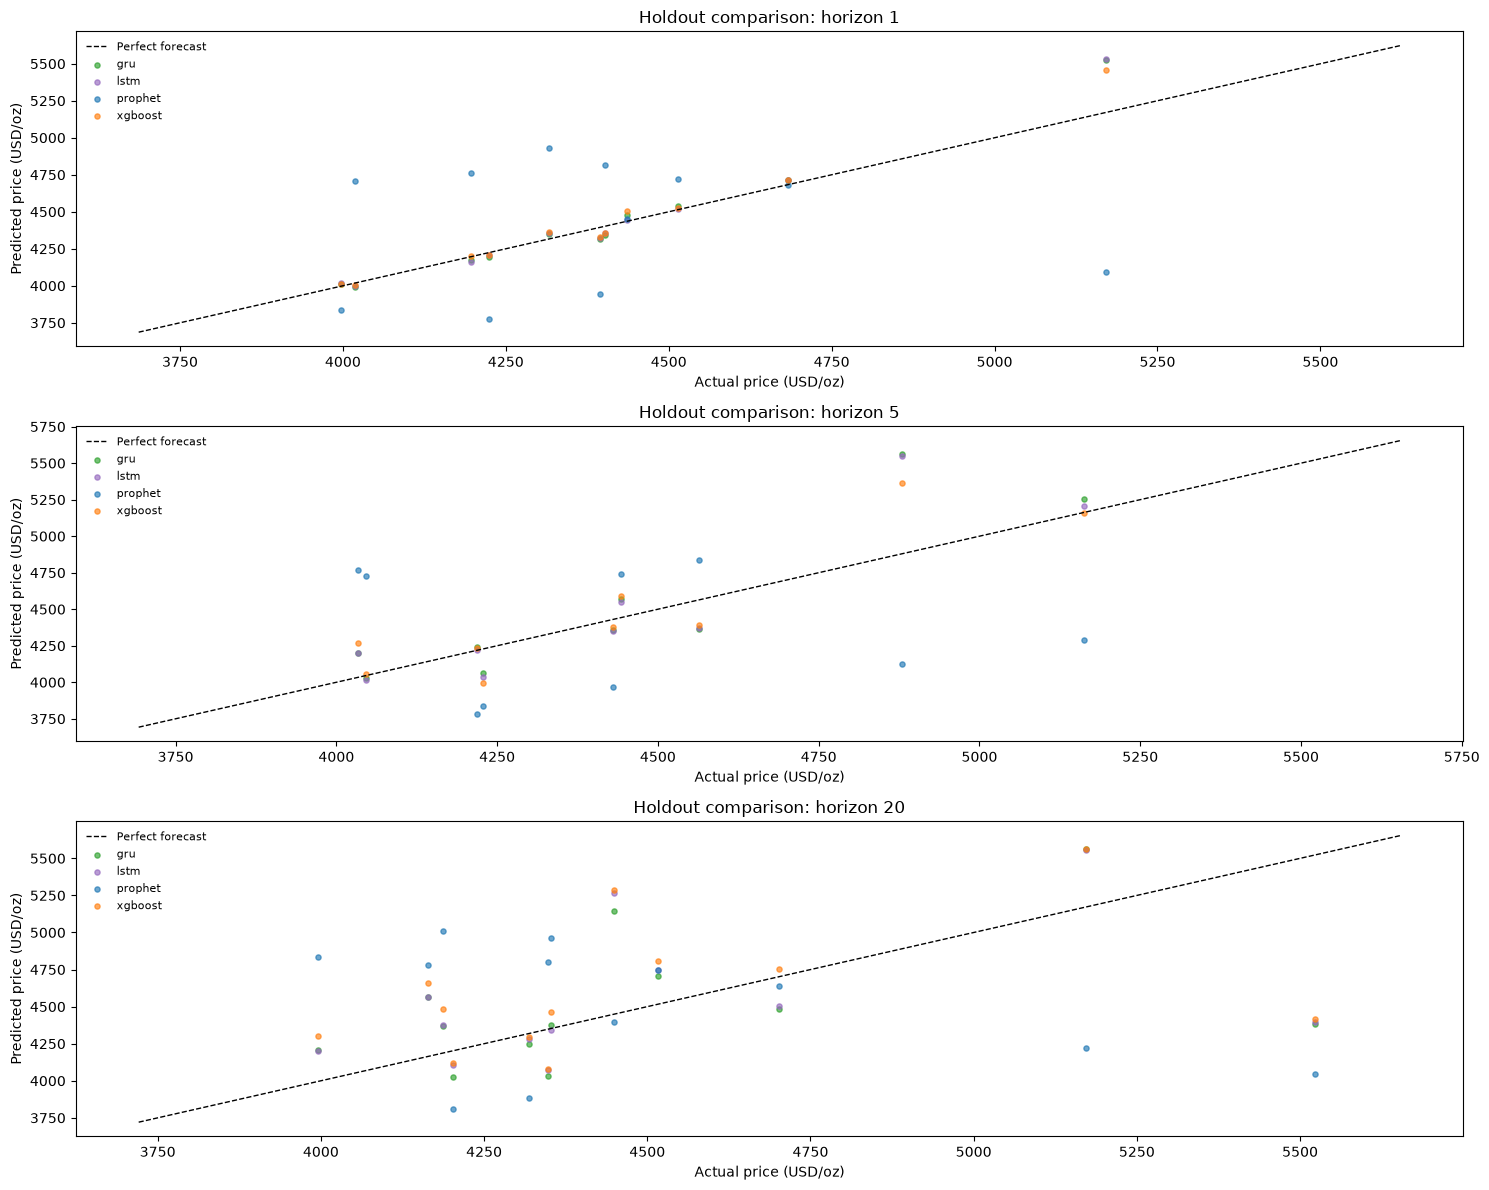

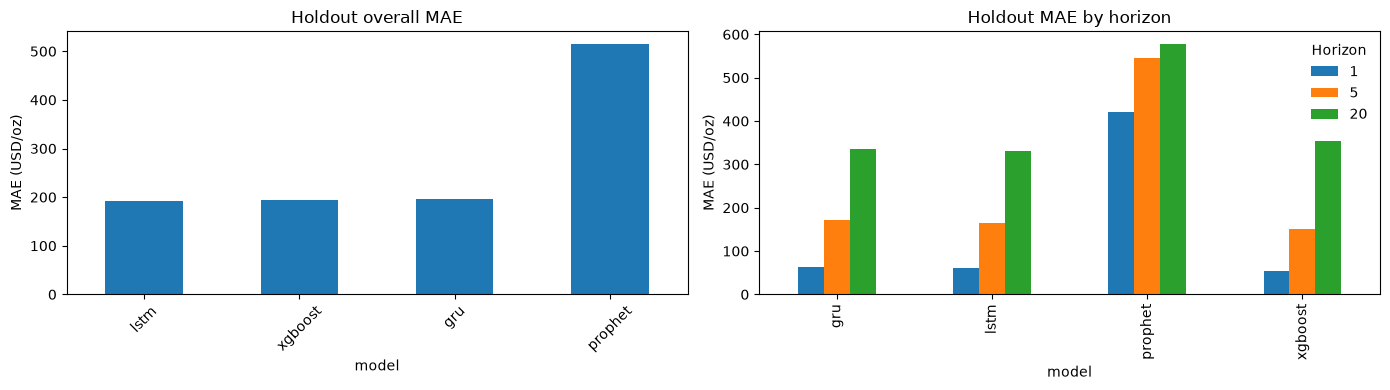

In [14]:
holdout_files = sorted((ROOT / 'artifacts').glob('*/holdout_predictions.csv'))
if len(holdout_files) >= 2:
    holdout_predictions = pd.concat(
        [pd.read_csv(path, parse_dates=['origin', 'target_date'])
         for path in holdout_files], ignore_index=True)
    out_dir = ROOT / 'artifacts' / 'comparison'
    plot_comparison_actual_and_forecasts(holdout_predictions, panel, folds, cfg, out_dir, stage='holdout')
    plot_comparison_by_fold(holdout_predictions, panel, folds, cfg, out_dir, stage='holdout')
    plot_comparison_scatter(holdout_predictions, panel, folds, cfg, out_dir, stage='holdout')
    plot_comparison_error_ranking(holdout_predictions, cfg, out_dir, stage='holdout')
else:
    print('Need at least two models with holdout predictions to compare them.')